# 04. Model Comparison — Klasifikasi Jenis Wine

Notebook ini menyajikan perbandingan hasil klasifikasi dari notebook 03. Notebook 03 menghitung evaluasi; notebook ini membaca hasil holdout dan cross-validation yang diekspor, lalu menyusun tabel dan visualisasi. Jalankan notebook 03 dari atas sampai sel terakhir terlebih dahulu.

## 1. Memuat Hasil Evaluasi

Hasil holdout berasal dari satu split test yang digunakan bersama oleh seluruh model. Hasil cross-validation final memakai outer 5-fold pada data latih; pencarian `k` KNN berlangsung di inner 5-fold setiap outer fold. Kedua evaluasi ditampilkan berdampingan untuk memberi gambaran hasil test dan variasi CV.

In [11]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data" / "processed" / "winequality_cleaned.csv").is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("winequality_cleaned.csv tidak ditemukan. Jalankan notebook dari proyek Wine.")
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORT_DIR = PROJECT_ROOT / "reports" / "classification"
test_path = REPORT_DIR / "classification_test_metrics.csv"
cv_path = REPORT_DIR / "classification_cv_metrics.csv"
missing_files = [path.name for path in (test_path, cv_path) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Hasil evaluasi belum tersedia: " + ", ".join(missing_files) + ". "
        "Jalankan notebook 03 dari atas sampai sel terakhir agar file dibuat di "
        f"{REPORT_DIR}."
    )

test_results = pd.read_csv(test_path)
cv_results = pd.read_csv(cv_path)
required_test = {"Model", "Accuracy", "Precision Macro", "Recall Macro", "F1-score Macro"}
required_cv = {"Model", "Accuracy Mean", "Accuracy Std", "Precision Macro Mean", "Recall Macro Mean", "F1 Macro Mean", "F1 Macro Std"}
if not required_test.issubset(test_results.columns) or not required_cv.issubset(cv_results.columns):
    raise ValueError("Format file hasil evaluasi tidak sesuai. Jalankan ulang notebook 03.")
if set(test_results["Model"]) != set(cv_results["Model"]):
    raise ValueError("Daftar model pada hasil holdout dan CV berbeda. Jalankan ulang notebook 03.")

comparison = test_results.merge(
    cv_results, on="Model", how="inner", validate="one_to_one",
)
comparison = comparison.sort_values("F1-score Macro", ascending=False).reset_index(drop=True)
print("Sumber hasil:", REPORT_DIR)
display(comparison)

Sumber hasil: d:\MachineLearning\Wine\reports\classification


,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro,Selected k,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,CV Design
0,KNN (tuned),0.996241,0.996259,0.993854,0.995049,1.0,0.991531,0.004171,0.988612,0.989165,0.988876,0.005460,5-fold outer CV; nested 5-fold KNN tuning
1,Random Forest,0.993421,0.991943,0.990753,0.991346,NaN,0.995531,0.002513,0.994895,0.993365,0.994100,0.003350,5-fold outer CV; nested 5-fold KNN tuning
2,Logistic Regression,0.992481,0.988977,0.991329,0.990146,NaN,0.992944,0.001969,0.991345,0.990114,0.990697,0.002644,5-fold outer CV; nested 5-fold KNN tuning
3,Decision Tree,0.978383,0.969011,0.974617,0.971770,NaN,0.980479,0.004625,0.972897,0.975990,0.974404,0.006101,5-fold outer CV; nested 5-fold KNN tuning


## 2. Visualisasi Holdout dan Cross-Validation

Paired dot plot menunjukkan skor holdout dan rata-rata outer CV untuk setiap model; whisker CV menunjukkan simpangan baku antar-fold. Rentang sumbu diperbesar secara terbuka agar skor yang berdekatan mudah dibaca, sementara nilai persis tetap ada di tabel.

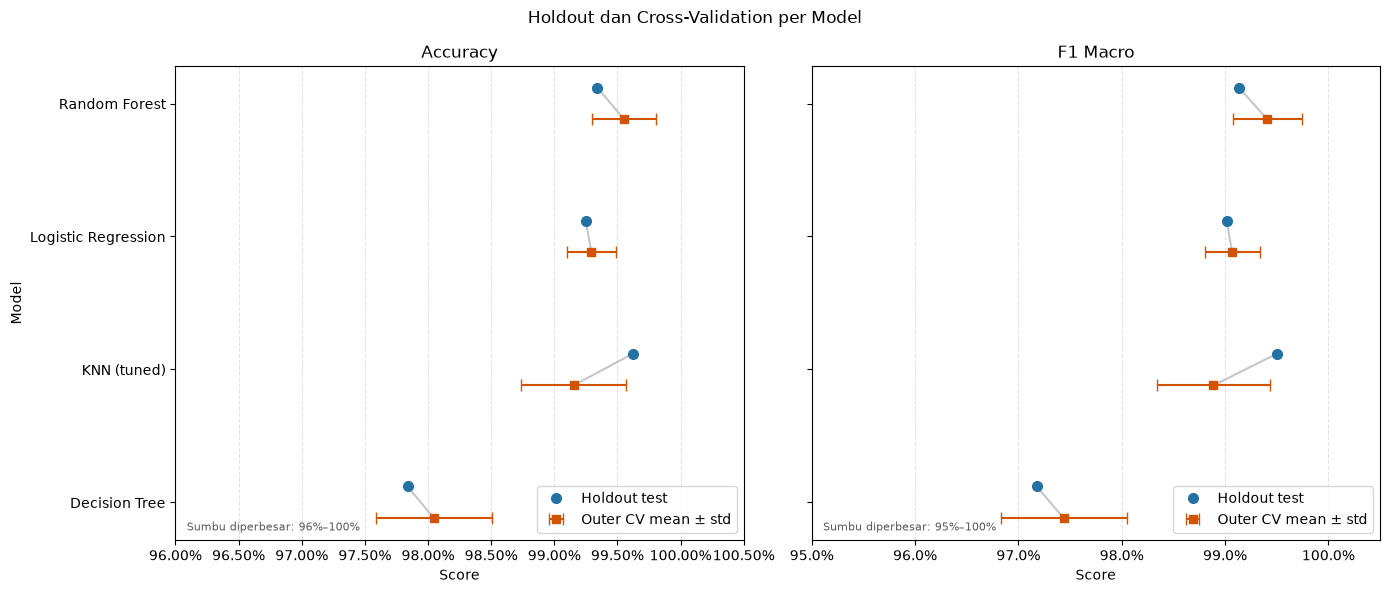

In [12]:
import numpy as np
from matplotlib.ticker import PercentFormatter

plot_specs = [
    ("Accuracy", "Accuracy Mean", "Accuracy Std", "Accuracy"),
    ("F1-score Macro", "F1 Macro Mean", "F1 Macro Std", "F1 Macro"),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, (test_col, cv_mean, cv_std, title) in zip(axes, plot_specs):
    plot_data = comparison.sort_values(cv_mean, ascending=True).reset_index(drop=True)
    y = np.arange(len(plot_data))
    holdout = plot_data[test_col].to_numpy()
    cv_values = plot_data[cv_mean].to_numpy()
    cv_std_values = plot_data[cv_std].to_numpy()
    for row, test_score, cv_score in zip(y, holdout, cv_values):
        ax.plot([test_score, cv_score], [row + 0.12, row - 0.12], color="0.78", linewidth=1.5, zorder=1)
    ax.errorbar(holdout, y + 0.12, fmt="o", markersize=7, color="#2471A3", label="Holdout test", zorder=3)
    ax.errorbar(cv_values, y - 0.12, xerr=cv_std_values, fmt="s", markersize=6, color="#D35400", ecolor="#D35400", capsize=4, label="Outer CV mean ± std", zorder=3)
    ax.set_title(title)
    ax.set_xlabel("Score")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["Model"])
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.legend(loc="lower right")
    lowest = min(float(holdout.min()), float((cv_values - cv_std_values).min()))
    lower_limit = max(0.0, np.floor((lowest - 0.015) * 100) / 100)
    ax.set_xlim(lower_limit, 1.005)
    ax.text(0.02, 0.02, f"Sumbu diperbesar: {lower_limit:.0%}–100%", transform=ax.transAxes, fontsize=8, color="0.35")
axes[0].set_ylabel("Model")
fig.suptitle("Holdout dan Cross-Validation per Model")
fig.tight_layout()
plt.show()

## 3. Cara Membaca Hasil

Tabel memuat seluruh metrik, sedangkan grafik memudahkan perbandingan Accuracy dan F1 Macro serta variasi antar-fold. Holdout adalah satu split; CV memberi gambaran variasi pada beberapa fold. Selisih keduanya perlu dibaca sebagai pemeriksaan kestabilan, bukan sebagai satu skor gabungan.